In [2]:
## Customer Churn Analysis and Prediction
## Saiket Systems – Data Analysis Internship

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [5]:
file_path = "Telco_Customer_Churn_Dataset .csv"
df = pd.read_csv("C:/Users/91969/Downloads/Telco_Customer_Churn_Dataset .csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.shape

(7043, 21)

In [7]:
df.info()
df.describe(include='all').T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [9]:
##TASK 1 — Data Cleaning and Preprocessing

missing = df.isnull().sum()
missing[missing > 0]

Series([], dtype: int64)

In [10]:
(df['TotalCharges'].astype(str).str.strip() == '').sum()

np.int64(11)

In [11]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
df[df['TotalCharges'].isnull()][
    ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df.isnull().sum().sum()

np.int64(0)

In [13]:
df.duplicated().sum()
df['customerID'].duplicated().sum()

np.int64(0)

In [14]:
df_model = df.drop(columns=['customerID'])

In [15]:
df['ChurnFlag'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})
df[['Churn', 'ChurnFlag']].head()

,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [16]:
##TASK 2 — Exploratory Data Analysis

churn_counts = df['Churn'].value_counts()
churn_counts

churn_rate = df['ChurnFlag'].mean() * 100
print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 26.54%


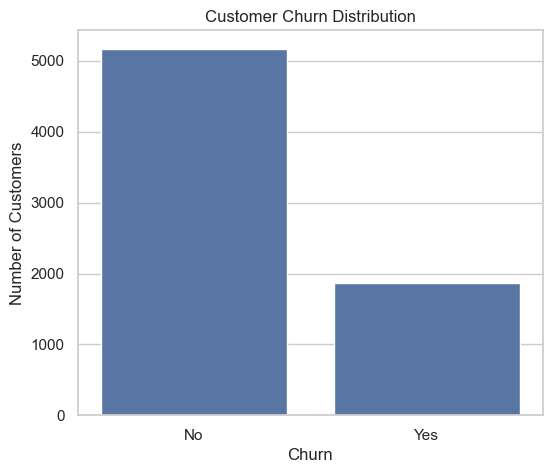

In [17]:
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [18]:
gender_churn = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100
gender_churn

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


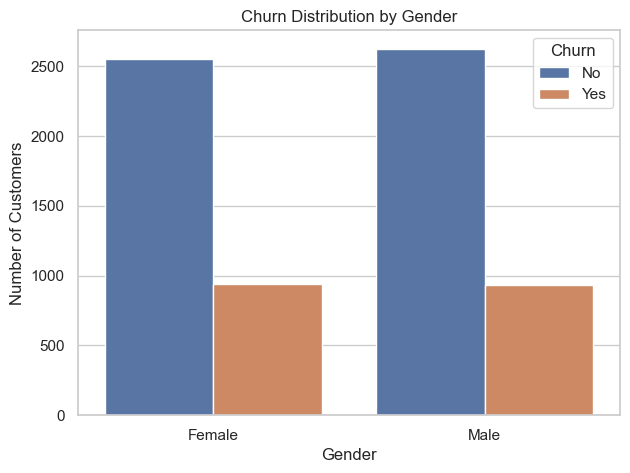

In [19]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='gender',
    hue='Churn'
)
plt.title('Churn Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

In [20]:
senior_churn = df.groupby('SeniorCitizen')['ChurnFlag'].mean() * 100
senior_churn

SeniorCitizen
0    23.606168
1    41.681261
Name: ChurnFlag, dtype: float64

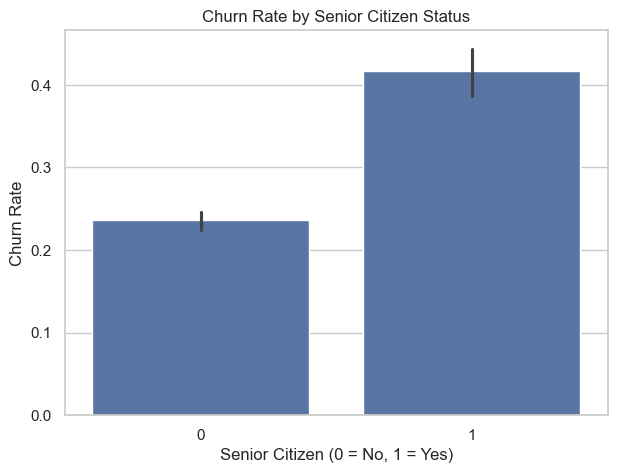

In [21]:
plt.figure(figsize=(7, 5))
sns.barplot(
    data=df,
    x='SeniorCitizen',
    y='ChurnFlag'
)
plt.title('Churn Rate by Senior Citizen Status')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate')
plt.show()

In [22]:
contract_churn = (
    df.groupby('Contract')['ChurnFlag']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
contract_churn

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: ChurnFlag, dtype: float64

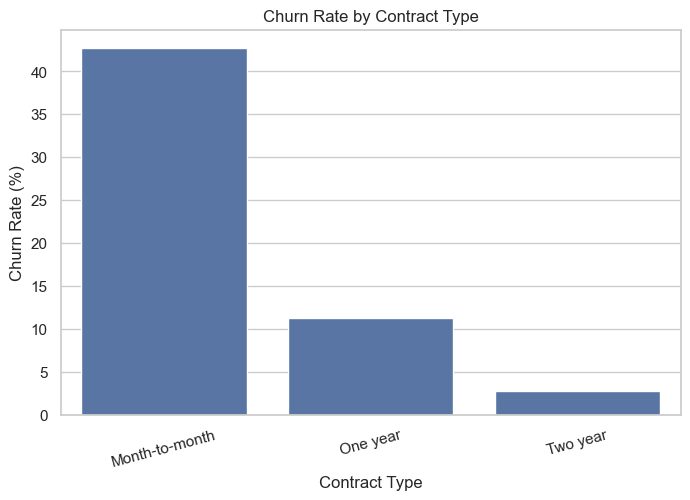

In [23]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)
plt.show()

In [24]:
payment_churn = (
    df.groupby('PaymentMethod')['ChurnFlag']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
payment_churn

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: ChurnFlag, dtype: float64

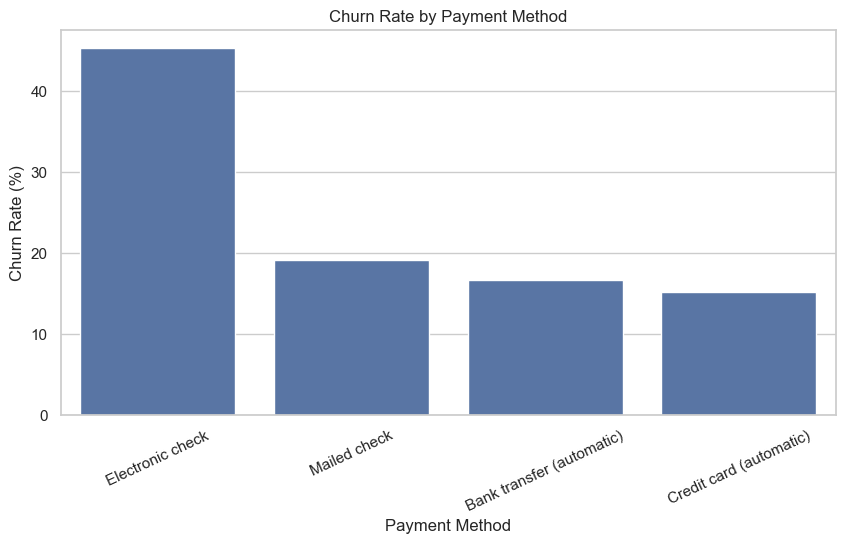

In [25]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)
plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=25)
plt.show()

In [26]:
internet_churn = (
    df.groupby('InternetService')['ChurnFlag']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
internet_churn

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: ChurnFlag, dtype: float64

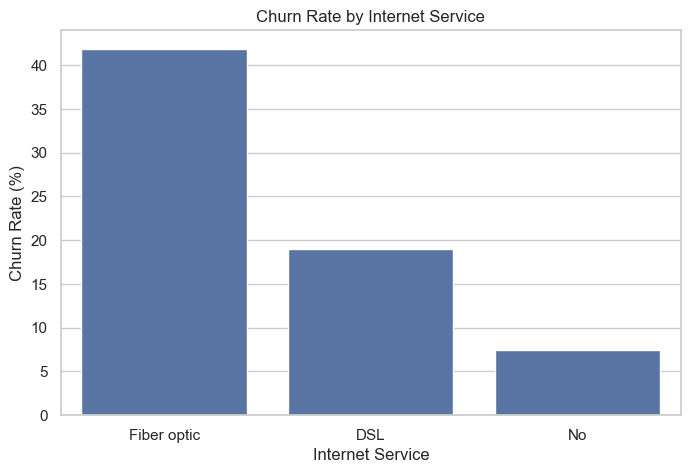

In [27]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)
plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.show()

In [28]:
df['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

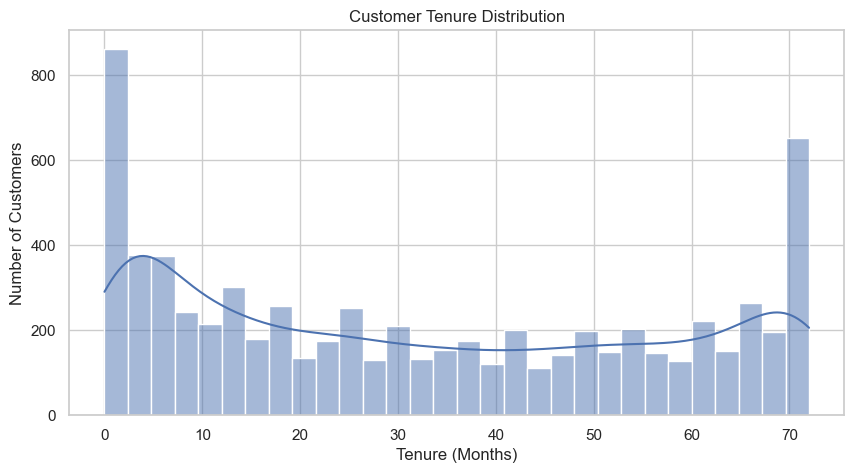

In [29]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='tenure',
    bins=30,
    kde=True
)
plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

In [33]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = [
    '0-6',
    '7-12',
    '13-24',
    '25-36',
    '37-48',
    '49-60',
    '61-72'
]
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels
)

In [34]:
tenure_churn = (
    df.groupby('TenureGroup', observed=False)['ChurnFlag']
    .mean()
    .mul(100)
)
tenure_churn

TenureGroup
0-6      53.333333
7-12     35.886525
13-24    28.710938
25-36    21.634615
37-48    19.028871
49-60    14.423077
61-72     6.609808
Name: ChurnFlag, dtype: float64

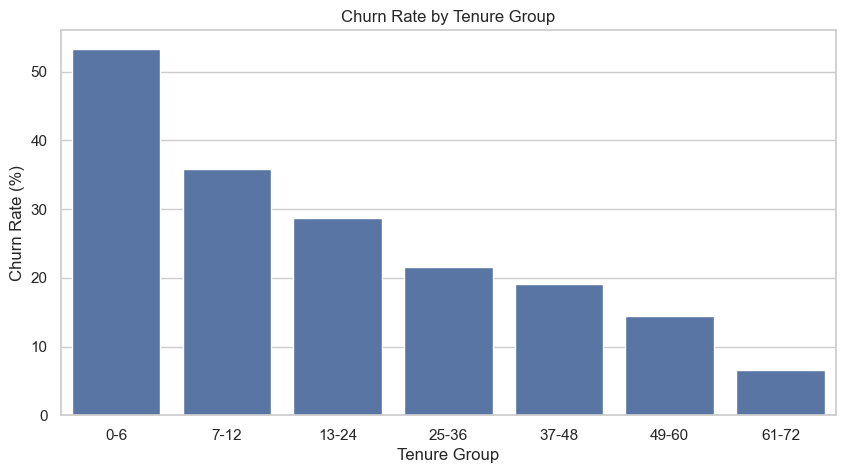

In [35]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)
plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.show()

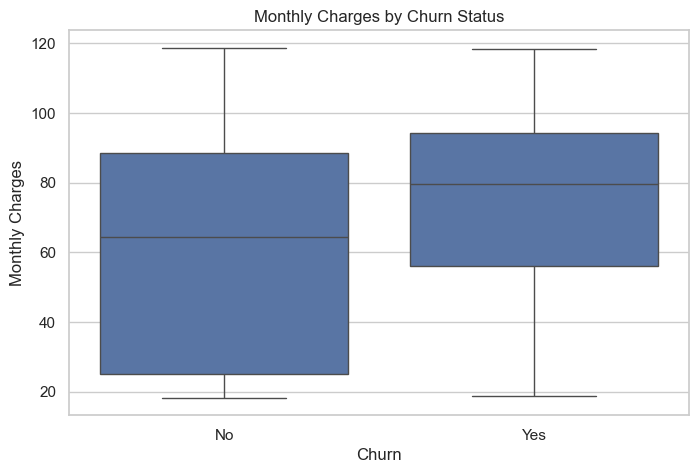

In [36]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

In [37]:
##TASK 3 — Customer Segmentation

df['TenureSegment'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 36, 72],
    labels=[
        'New (0-12 months)',
        'Mid (13-36 months)',
        'Loyal (37-72 months)'
    ]
)
df['TenureSegment'].value_counts()

TenureSegment
Loyal (37-72 months)    3001
New (0-12 months)       2175
Mid (13-36 months)      1856
Name: count, dtype: int64

In [38]:
df['ChargeSegment'] = pd.cut(
    df['MonthlyCharges'],
    bins=[-np.inf, 50, 80, np.inf],
    labels=[
        'Low (<=50)',
        'Medium (51-80)',
        'High (>80)' ])

In [39]:
segment_analysis = (
    df.groupby(
        ['TenureSegment', 'ChargeSegment', 'Contract'],
        observed=False )
    .agg(
        Customers=('customerID', 'count'),
        Churned=('ChurnFlag', 'sum'),
        ChurnRate=('ChurnFlag', 'mean') )
    .reset_index()  )
segment_analysis['ChurnRate'] *= 100
segment_analysis.sort_values(
    'ChurnRate',
    ascending=False
).head(15)

,TenureSegment,ChargeSegment,Contract,Customers,Churned,ChurnRate
6,New (0-12 months),High (>80),Month-to-month,464,341,73.491379
3,New (0-12 months),Medium (51-80),Month-to-month,754,405,53.713528
15,Mid (13-36 months),High (>80),Month-to-month,575,278,48.347826
0,New (0-12 months),Low (<=50),Month-to-month,776,278,35.824742
24,Loyal (37-72 months),High (>80),Month-to-month,426,145,34.037559
12,Mid (13-36 months),Medium (51-80),Month-to-month,388,116,29.896907
7,New (0-12 months),High (>80),One year,7,2,28.571429
21,Loyal (37-72 months),Medium (51-80),Month-to-month,154,35,22.727273
16,Mid (13-36 months),High (>80),One year,89,19,21.348315
18,Loyal (37-72 months),Low (<=50),Month-to-month,78,15,19.230769


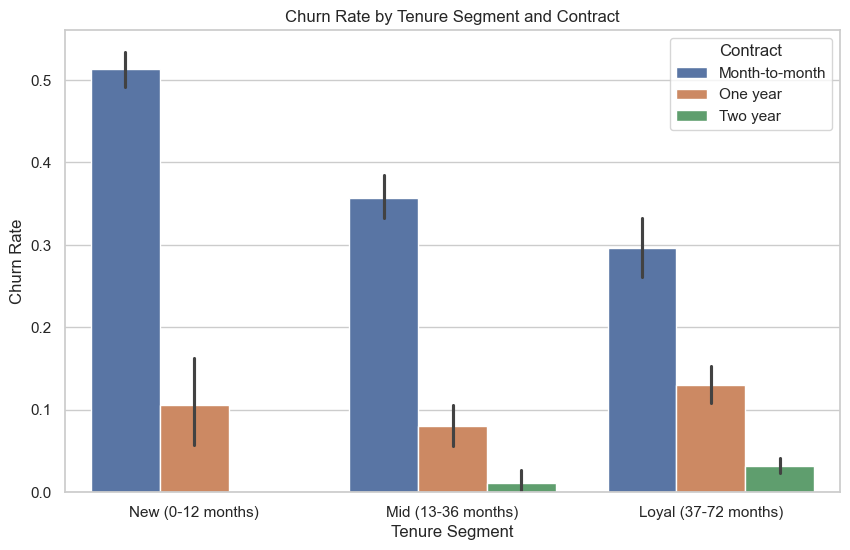

In [40]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x='TenureSegment',
    y='ChurnFlag',
    hue='Contract'
)
plt.title('Churn Rate by Tenure Segment and Contract')
plt.xlabel('Tenure Segment')
plt.ylabel('Churn Rate')
plt.legend(title='Contract')
plt.show()

In [11]:
import pandas as pd
# Load the dataset
df = pd.read_csv("Telco_Customer_Churn_Dataset .csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)
# Fill missing TotalCharges
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print("Missing values:")
print(df.isnull().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [14]:
## TASK 4 — CHURN PREDICTION MODEL


model_df = df.copy()
columns_to_drop = [
    'customerID',
    'ChurnFlag',
    'TenureGroup',
    'TenureSegment',
    'ChargeSegment'
]
model_df = model_df.drop(
    columns=[
        col for col in columns_to_drop
        if col in model_df.columns
    ]
)
print("Model dataset shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

Model dataset shape: (7043, 20)

Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [15]:
print("\nChurn distribution:")
print(model_df['Churn'].value_counts())


Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [16]:
X = model_df.drop(columns=['Churn'])
y = model_df['Churn'].map({
    'No': 0,
    'Yes': 1
})
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [17]:
categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()
numerical_columns = X.select_dtypes(
    exclude=['object']
).columns.tolist()
print("Categorical columns:")
print(categorical_columns)
print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
    transformers=[ (  'num',
            StandardScaler(),
            numerical_columns ),('cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns ) ])
print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
model = Pipeline(
    steps=[  ('preprocessor', preprocessor), (  'classifier',
            LogisticRegression(max_iter=1000)  ) ])
print("Logistic Regression model created!")

Logistic Regression model created!


In [21]:
model.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [22]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
print("Prediction completed successfully!")

Prediction completed successfully!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score )
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)
print("===== MODEL PERFORMANCE =====")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

===== MODEL PERFORMANCE =====
Accuracy  : 0.8055
Precision : 0.6572
Recall    : 0.5588
F1 Score  : 0.6040
ROC-AUC   : 0.8421


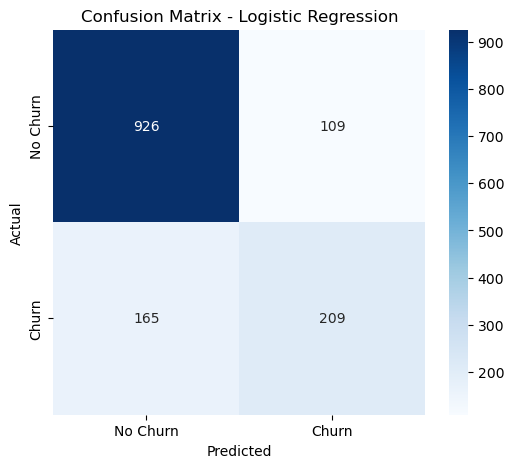

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [27]:
## TASK 5 —Customer Retention Strategies

df['EstimatedLTV'] = (
    df['MonthlyCharges'] * df['tenure'])
df[ [ 'customerID',
        'tenure',
        'MonthlyCharges',
        'EstimatedLTV',
        'Churn' ]].head()

,customerID,tenure,MonthlyCharges,EstimatedLTV,Churn
0,7590-VHVEG,1,29.85,29.85,No
1,5575-GNVDE,34,56.95,1936.30,No
2,3668-QPYBK,2,53.85,107.70,Yes
3,7795-CFOCW,45,42.30,1903.50,No
4,9237-HQITU,2,70.70,141.40,Yes


In [28]:
df['EstimatedLTV'].describe()

count    7043.000000
mean     2279.581350
std      2264.729447
min         0.000000
25%       394.000000
50%      1393.600000
75%      3786.100000
max      8550.000000
Name: EstimatedLTV, dtype: float64

In [29]:
print(
    f"Average Estimated LTV: ${df['EstimatedLTV'].mean():.2f}")
print(
    f"Median Estimated LTV: ${df['EstimatedLTV'].median():.2f}")
print(
    f"Maximum Estimated LTV: ${df['EstimatedLTV'].max():.2f}")

Average Estimated LTV: $2279.58
Median Estimated LTV: $1393.60
Maximum Estimated LTV: $8550.00


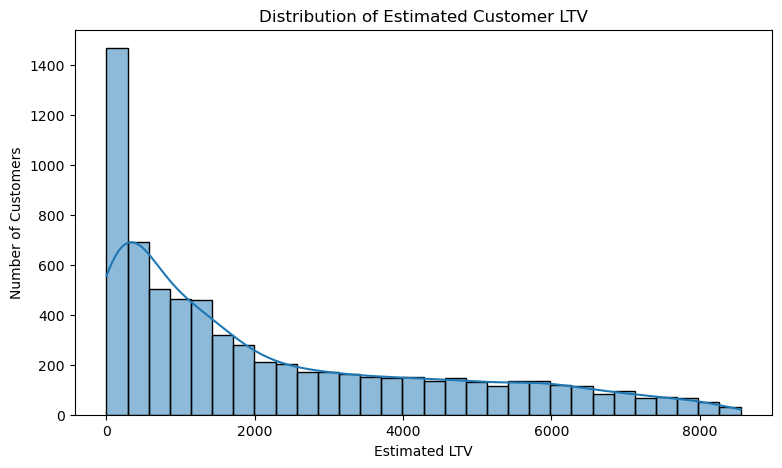

In [30]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x='EstimatedLTV',
    bins=30,
    kde=True)
plt.title('Distribution of Estimated Customer LTV')
plt.xlabel('Estimated LTV')
plt.ylabel('Number of Customers')
plt.show()

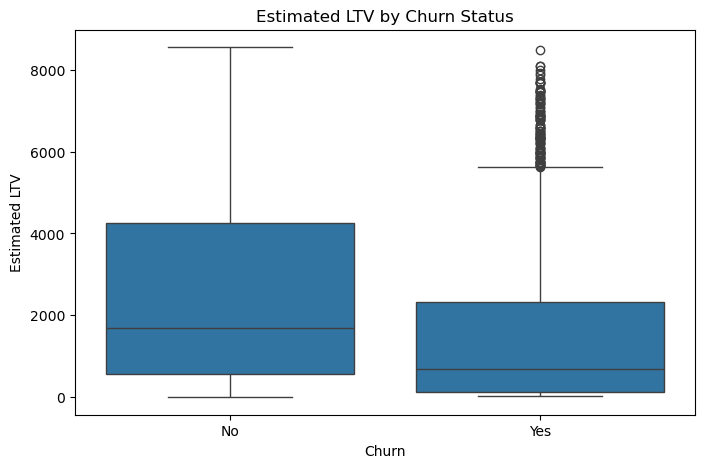

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='EstimatedLTV')
plt.title('Estimated LTV by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Estimated LTV')
plt.show()

In [32]:
df['ValueSegment'] = pd.qcut(
    df['EstimatedLTV'],
    q=3,
    labels=[
        'Low Value',
        'Medium Value',
        'High Value' ],
    duplicates='drop')
print(df['ValueSegment'].value_counts())

ValueSegment
Low Value       2349
High Value      2348
Medium Value    2346
Name: count, dtype: int64


In [36]:
# PREDICT CHURN PROBABILITY
risk_input = df.copy()
columns_to_drop = [
    'customerID',
    'Churn',
    'ChurnFlag',
    'TenureGroup',
    'TenureSegment',
    'ChargeSegment',
    'EstimatedLTV',
    'ValueSegment']
risk_input = risk_input.drop(
    columns=[
        col for col in columns_to_drop
        if col in risk_input.columns])
print("Risk input shape:", risk_input.shape)

Risk input shape: (7043, 19)


In [37]:
df['ChurnProbability'] = model.predict_proba(
    risk_input
)[:, 1]
df[ [ 'customerID',
        'Churn',
        'ChurnProbability' ]
].head()

,customerID,Churn,ChurnProbability
0,7590-VHVEG,No,0.613717
1,5575-GNVDE,No,0.044497
2,3668-QPYBK,Yes,0.299185
3,7795-CFOCW,No,0.028452
4,9237-HQITU,Yes,0.691580


In [38]:
# CUSTOMER RISK CATEGORY

def classify_risk(probability):
    if probability >= 0.70:
        return 'High Risk'
    elif probability >= 0.40:
        return 'Medium Risk'
    else:
        return 'Low Risk'
df['RiskCategory'] = df['ChurnProbability'].apply(
    classify_risk)
df[ [  'customerID',
        'ChurnProbability',
        'RiskCategory' ]
].head()

,customerID,ChurnProbability,RiskCategory
0,7590-VHVEG,0.613717,Medium Risk
1,5575-GNVDE,0.044497,Low Risk
2,3668-QPYBK,0.299185,Low Risk
3,7795-CFOCW,0.028452,Low Risk
4,9237-HQITU,0.691580,Medium Risk


RiskCategory
Low Risk       4944
Medium Risk    1603
High Risk       496
Name: count, dtype: int64


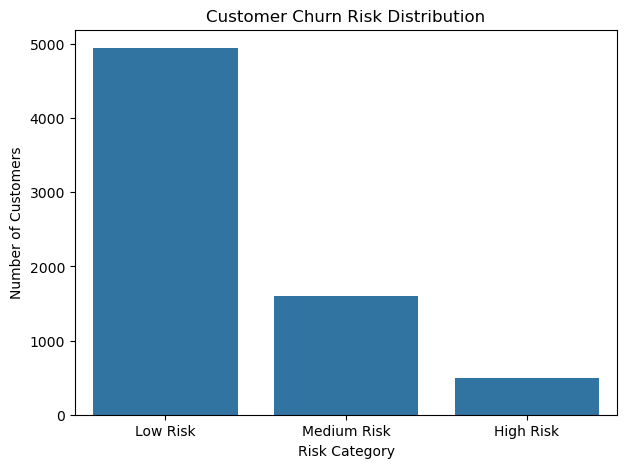

In [39]:
risk_counts = df['RiskCategory'].value_counts()
print(risk_counts)

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='RiskCategory',
    order=['Low Risk', 'Medium Risk', 'High Risk'])
plt.title('Customer Churn Risk Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')
plt.show()

In [40]:
# HIGH-VALUE CUSTOMERS AT RISK
high_value_at_risk = df[
    (df['ValueSegment'] == 'High Value') &
    (df['RiskCategory'] == 'High Risk')
].copy()
print(  "High-value high-risk customers:",
    len(high_value_at_risk))

high_value_at_risk[ [   'customerID',
        'tenure',
        'MonthlyCharges',
        'EstimatedLTV',
        'Contract',
        'PaymentMethod',
        'ChurnProbability',
        'RiskCategory',
        'Churn' ]
].sort_values(
    'ChurnProbability',
    ascending=False
).head(20)

High-value high-risk customers: 3


,customerID,tenure,MonthlyCharges,EstimatedLTV,Contract,PaymentMethod,ChurnProbability,RiskCategory,Churn
2163,4021-RQSNY,29,98.5,2856.5,Month-to-month,Electronic check,0.733298,High Risk,Yes
2085,8290-YWKHZ,32,93.2,2982.4,Month-to-month,Electronic check,0.703622,High Risk,Yes
724,5244-IRFIH,33,94.5,3118.5,Month-to-month,Electronic check,0.700708,High Risk,Yes


In [43]:
active_high_value_risk = df[
    (df['Churn'] == 'No') &
    (df['ValueSegment'] == 'High Value') &
    (df['RiskCategory'] == 'High Risk')
].copy()
print( "Active high-value customers at high churn risk:",
    len(active_high_value_risk))

active_high_value_risk[ [
        'customerID',
        'tenure',
        'MonthlyCharges',
        'EstimatedLTV',
        'Contract',
        'PaymentMethod',
        'InternetService',
        'ChurnProbability']
].sort_values(
    'ChurnProbability',
    ascending=False
).head(20)


Active high-value customers at high churn risk: 0


,customerID,tenure,MonthlyCharges,EstimatedLTV,Contract,PaymentMethod,InternetService,ChurnProbability


In [44]:
high_risk_contract = pd.crosstab(
    df['Contract'],
    df['RiskCategory'],
    normalize='index'
) * 100
display(high_risk_contract)

high_risk_payment = pd.crosstab(
    df['PaymentMethod'],
    df['RiskCategory'],
    normalize='index'
) * 100
display(high_risk_payment)

high_risk_internet = pd.crosstab(
    df['InternetService'],
    df['RiskCategory'],
    normalize='index'
) * 100
display(high_risk_internet)

RiskCategory,High Risk,Low Risk,Medium Risk
Contract,,,
Month-to-month,12.8,46.348387,40.851613
One year,0.0,98.642227,1.357773
Two year,0.0,100.000000,0.000000


RiskCategory,High Risk,Low Risk,Medium Risk
PaymentMethod,,,
Bank transfer (automatic),0.582902,86.204663,13.212435
Credit card (automatic),0.394218,87.319317,12.286465
Electronic check,19.830867,39.365751,40.803383
Mailed check,0.744417,83.933002,15.322581


RiskCategory,High Risk,Low Risk,Medium Risk
InternetService,,,
DSL,0.454358,83.973565,15.572078
Fiber optic,15.665375,44.735142,39.599483
No,0.000000,100.000000,0.000000


In [45]:
priority_summary = pd.DataFrame({
    'Risk Category': [
        'High Risk',
        'Medium Risk',
        'Low Risk'  ],
    'Customers': [
        (df['RiskCategory'] == 'High Risk').sum(),
        (df['RiskCategory'] == 'Medium Risk').sum(),
        (df['RiskCategory'] == 'Low Risk').sum() ] })
priority_summary['Percentage'] = (
    priority_summary['Customers']
    / len(df)
    * 100)
priority_summary

,Risk Category,Customers,Percentage
0,High Risk,496,7.042453
1,Medium Risk,1603,22.760187
2,Low Risk,4944,70.197359


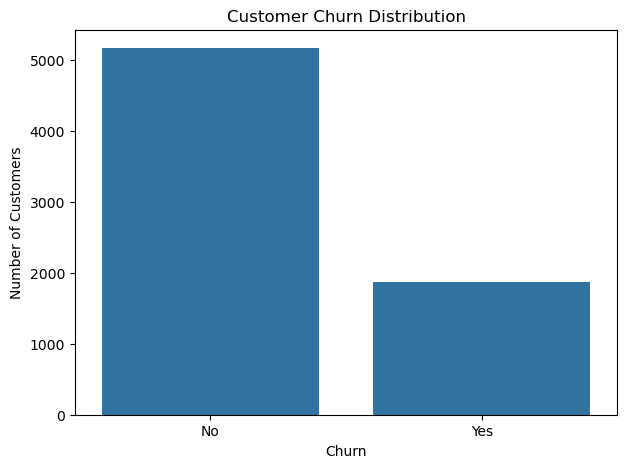

In [47]:
# TASK 6 — ADVANCED DATA VISUALIZATIONS

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

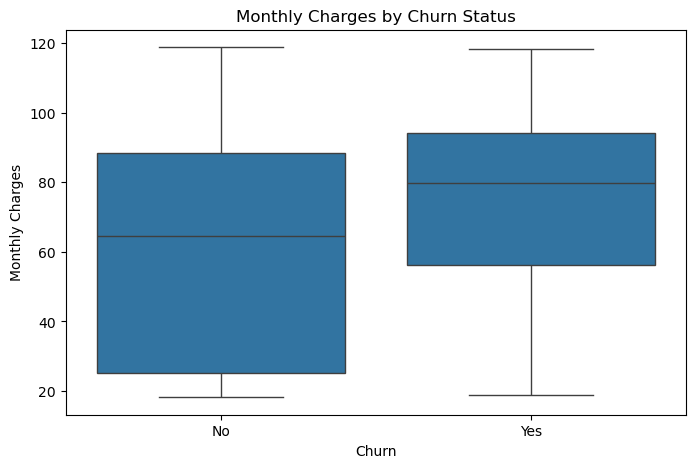

In [48]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges')
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

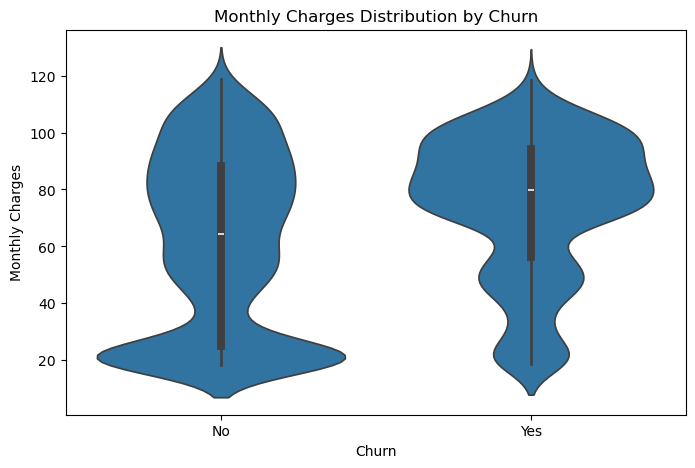

In [49]:
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)
plt.title('Monthly Charges Distribution by Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

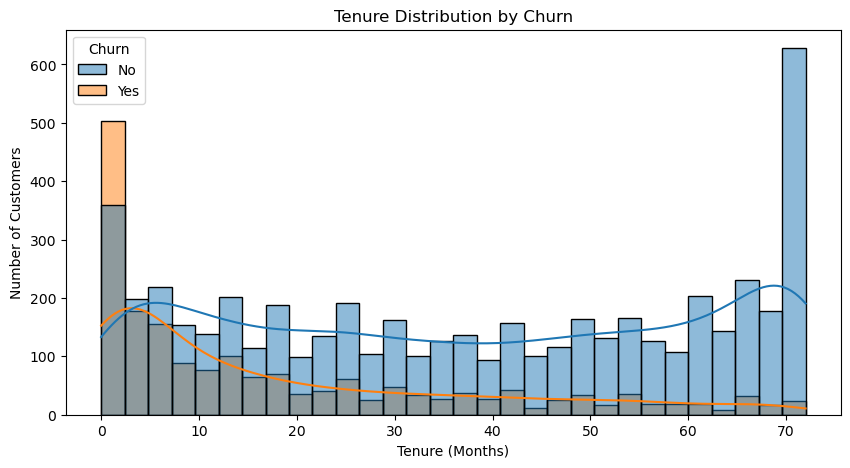

In [51]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True)
plt.title('Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

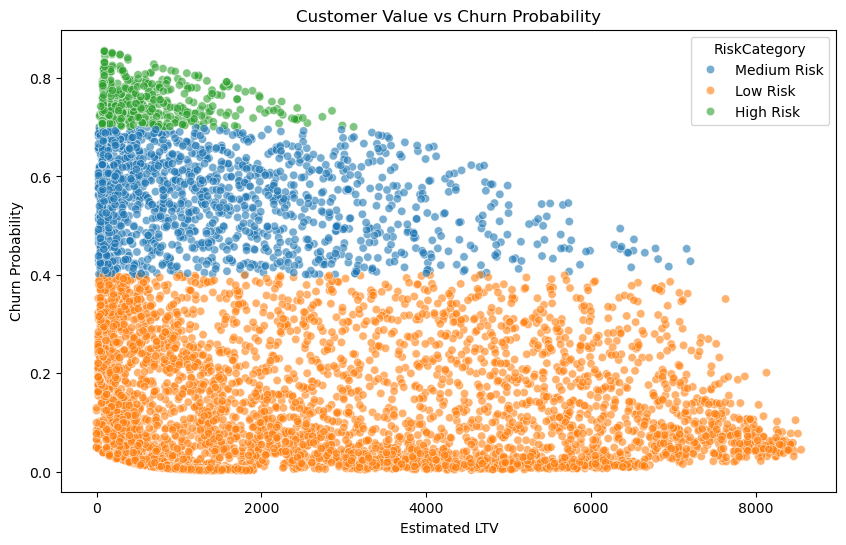

In [53]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='EstimatedLTV',
    y='ChurnProbability',
    hue='RiskCategory',
    alpha=0.6)
plt.title('Customer Value vs Churn Probability')
plt.xlabel('Estimated LTV')
plt.ylabel('Churn Probability')
plt.show()

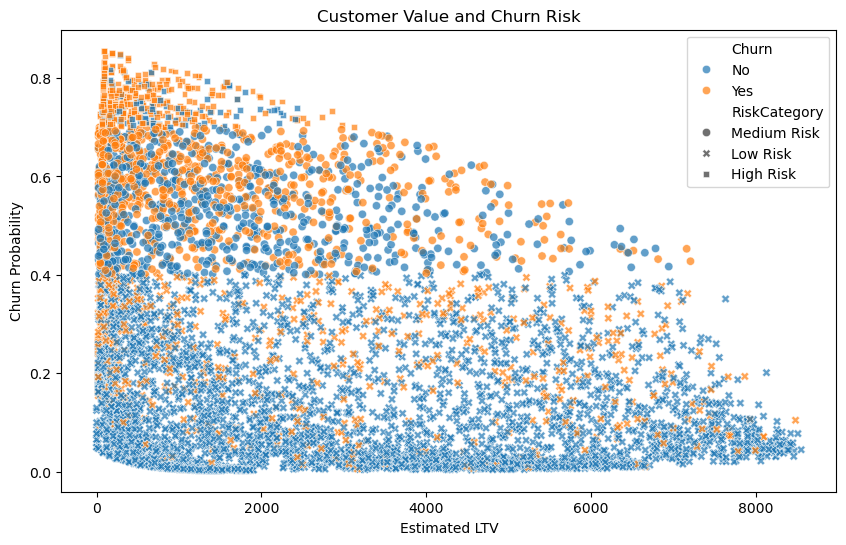

In [54]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='EstimatedLTV',
    y='ChurnProbability',
    hue='Churn',
    style='RiskCategory',
    alpha=0.7)
plt.title('Customer Value and Churn Risk')
plt.xlabel('Estimated LTV')
plt.ylabel('Churn Probability')
plt.show()